# Support Vector Regression: TMDB viewer rating
Predict `vote_average` from `../../data/model_data_rating.csv`. Uses an RBF kernel to model nonlinear patterns, with a small error tolerance and regularization. Scaling is especially important for this model.

Use the fixed 2017-11-18 chronological cutoff and three training-period validation splits as `linear_model.ipynb`. Compare with the training-mean baseline and the same cumulative feature groups. Initial and training-validation-selected settings are compared below.

Run all cells from `Modeling_scripts/rating_models/` with the `ds6001` kernel. The notebook reads the feature-engineering output without changing CSVs or exporting model files.

Section 4 validates/tunes settings without using the later test data to choose them.

The current model table includes directors' earlier-year rating history, its supporting film count, and a no-history flag. These use retrospective ratings on strictly earlier films; the target movie's rating is still excluded from predictors.

`log_budget` is the base-10 log of reported production budget. Unknown budgets remain missing in rating data and are median-imputed using training rows only. Current revenue and outcomes are excluded from predictors.

## Tuning controls — edit here first

1. Edit the controls in the next cell.
2. **Save the notebook and Run All** so every result uses the same settings.
3. Review the validation table, then the later-test table. Do not repeatedly tune against test scores.

| What you want to change | Control |
|---|---|
| Original model or a setting not searched | `MODEL_SETTINGS` |
| Trial values for model settings | `PARAM_GRID` (lists); these override `MODEL_SETTINGS` during search |
| Which score selects settings | `TUNING_METRIC` |
| Feature groups to compare | `FEATURE_GROUPS_TO_COMPARE` |
| Date boundary and number of validation folds | `CUTOFF_DATE`, `N_VALIDATION_SPLITS`; keep consistent across models |

`C` controls fit flexibility; `gamma` controls how local the RBF patterns are.

**Example:** Try the `C` and `gamma` lists in `PARAM_GRID`. Change one list at a time so the experiment is interpretable. Keep parameter key names unchanged when editing trial values.

In [1]:
# EDIT THIS CELL, then save and Run All. Do not change settings in later cells.
DATA_FILE = "../../data/model_data_rating.csv"
CUTOFF_DATE = "2017-11-18"  # Change consistently across models for a fair comparison.
N_VALIDATION_SPLITS = 3     # Expanding chronological folds inside training.

# Fixed original-model settings. Grid values below override these during a search.
MODEL_SETTINGS = {'kernel': 'rbf', 'C': 1.0, 'epsilon': 0.1}

# CHANGE THESE LISTS to try model settings. More values mean a longer run.
# Empty for OLS: use Ridge for regularization, or change feature groups below.
PARAM_GRID = {'regression__C': [0.5, 1.0, 5.0], 'regression__gamma': ['scale', 0.01]}
TUNING_METRIC = "MAE"
# MAE/RMSE: lower is better. R2: higher is better.

# Remove a group to skip it; keep All features for the reference comparison.
FEATURE_GROUPS_TO_COMPARE = [
    "Movie characteristics", "+ Director history", "+ Actor history", "All features",
]
assert "All features" in FEATURE_GROUPS_TO_COMPARE

assert isinstance(N_VALIDATION_SPLITS, int) and N_VALIDATION_SPLITS >= 2

assert set(FEATURE_GROUPS_TO_COMPARE) <= {"Movie characteristics", "+ Director history", "+ Actor history", "All features"}


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.svm import SVR
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

movies = pd.read_csv(DATA_FILE, parse_dates=["release_date"])
movies = movies.sort_values("release_date", kind="stable").reset_index(drop=True)
assert movies["tmdb_id"].is_unique
assert movies["release_date"].notna().all()
assert movies["vote_average"].notna().all() and movies["vote_average"].between(0, 10).all()
print(f"Loaded {len(movies):,} movies | Target: vote_average")

Loaded 13,276 movies | Target: vote_average


## 1. Select predictors
Exclude the current-movie outcome (`vote_average`) and movie identifiers from the inputs. Keep release year numeric and treat release month as categorical.

In [3]:
ID_COLUMNS = ["tmdb_id", "imdb_id", "title_tmdb", "release_date"]
TARGET_COLUMNS = ["vote_average"]
NUMERIC_FEATURES = [
    "runtime", "log_budget", "release_year", "n_genres", "imdb_director_count",
    "dir_prior_success_rate_smoothed", "dir_prior_rating_smoothed",
    "dir_prior_rated_films_log1p", "dir_prior_films_log1p",
    "dir_years_active_log1p", "dir_prior_known_films_log1p",
    "lead_actor_films_5yr_backfilled_log1p", "company_films_5yr_log1p",
    "franchise_prior_films_log1p",
]
CATEGORICAL_FEATURES = ["us_certification", "release_month"]
BINARY_FEATURES = [
    "is_sequel", "is_english", "dir_first_film", "dir_no_track_record", "backfill_unavailable", "dir_no_rating_history",
] + [column for column in movies if column.startswith("genre_")]
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES + BINARY_FEATURES
assert len(FEATURE_COLUMNS) == len(set(FEATURE_COLUMNS))
assert set(movies) == set(ID_COLUMNS + TARGET_COLUMNS + FEATURE_COLUMNS)
assert not set(ID_COLUMNS + TARGET_COLUMNS) & set(FEATURE_COLUMNS)
assert not {"budget", "revenue", "revenue_to_budget", "popularity", "vote_count"} & set(FEATURE_COLUMNS)
assert movies[BINARY_FEATURES].isin([0, 1]).all().all()

X = movies[FEATURE_COLUMNS].copy()
# String conversion is a fixed type conversion, not a learned transformation.
for column in CATEGORICAL_FEATURES:
    X[column] = X[column].map(lambda value: str(value) if pd.notna(value) else np.nan)
y = movies["vote_average"].copy()
print(f"Predictors: {len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical, {len(BINARY_FEATURES)} binary")

Predictors: 14 numeric, 2 categorical, 24 binary


## 2. Split by release date
Read `model_data_rating.csv`, built from the broader combined data without budget/revenue filters. Retain the previous experiment's fixed date cutoff **2017-11-18**: train before it and test on or after it. All movies sharing a date stay together. The expanded cohort has 9,405 training and 3,871 test movies (about 71/29, rather than the previous 80/20).

Training-only chronological folds are rebuilt within this expanded training set. Broader test-population scores are not directly comparable with earlier scores on only financially eligible movies. These data have already been inspected, so results remain exploratory.

In [4]:
cutoff = pd.Timestamp(CUTOFF_DATE)
train_mask = movies["release_date"].lt(cutoff)
test_mask = ~train_mask
X_train, X_test = X.loc[train_mask].copy(), X.loc[test_mask].copy()
y_train, y_test = y.loc[train_mask].copy(), y.loc[test_mask].copy()
assert len(X_train) > 0 and len(X_test) > 0
assert movies.loc[train_mask, "release_date"].max() < movies.loc[test_mask, "release_date"].min()
assert set(movies.loc[train_mask, "tmdb_id"]).isdisjoint(movies.loc[test_mask, "tmdb_id"])
display(pd.DataFrame([
    ["Training", int(train_mask.sum()), movies.loc[train_mask, "release_date"].min(), movies.loc[train_mask, "release_date"].max()],
    ["Test", int(test_mask.sum()), movies.loc[test_mask, "release_date"].min(), movies.loc[test_mask, "release_date"].max()],
], columns=["Split", "Movies", "First release", "Last release"]))

,Split,Movies,First release,Last release
0,Training,9405,1990-01-12,2017-11-17
1,Test,3871,2017-11-18,2025-12-28


## 3. Fit Support Vector Regression
Build the original reference model with **`MODEL_SETTINGS` in the top Tuning controls cell**. Change searched values in `PARAM_GRID` where available; values in that grid override the original settings during search. The simple notebooks keep the estimator fixed across feature presets.

Imputation, scaling, and categorical encoding are fitted on training data only. Binary flags pass through unchanged. No current-movie outcome is a predictor.

In [5]:
def make_regression_model(columns):
    """Fresh preprocessing and regression for each feature set and split."""
    numeric = [column for column in NUMERIC_FEATURES if column in columns]
    categorical = [column for column in CATEGORICAL_FEATURES if column in columns]
    binary = [column for column in BINARY_FEATURES if column in columns]
    assert set(numeric + categorical + binary) == set(columns)
    preprocessing = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)),
        ]), categorical),
        ("binary", "passthrough", binary),
    ])
    return Pipeline([
        ("preprocessor", preprocessing),
        ("regression", SVR(**MODEL_SETTINGS)),
    ])

initial_model = make_regression_model(FEATURE_COLUMNS)
initial_model.fit(X_train, y_train)
initial_train_predictions = initial_model.predict(X_train)
initial_test_predictions = initial_model.predict(X_test)

baseline = DummyRegressor(strategy="mean")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
baseline_predictions = baseline.predict(np.zeros((len(y_test), 1)))
assert np.allclose(baseline_predictions, y_train.mean())
print(f"Training mean rating (baseline): {y_train.mean():.3f}")

Training mean rating (baseline): 6.399


## 4. Validation and tuning
Tune the regularization/error penalty (`C`) and RBF kernel width (`gamma`); keep epsilon at 0.1.

Use three expanding chronological validation folds inside the earlier training period. Every candidate refits the full preprocessing pipeline on its own fold. Select by **MAE** (lower is better); RMSE and R² are also shown.

`PARAM_GRID` controls the search; `TUNING_METRIC` controls selection. Refit the selected setting on all outer training movies, then show its test results once alongside the original model. Test data does not select settings. Search scores are selection scores, not independent estimates; do not repeatedly change the grid after inspecting the already-examined test period.

**Change settings in the Tuning controls cell at the top, save, then Run All. The code below uses those settings; do not redefine them here.**

In [6]:
from sklearn.model_selection import GridSearchCV

# Three expanding validation windows entirely within the outer training period.
tuning_dates = movies.loc[train_mask, "release_date"]
assert tuning_dates.index.equals(X_train.index)
unique_tuning_dates = np.sort(tuning_dates.unique())
tuning_splits = []
tuning_periods = []
for fold, (earlier, later) in enumerate(TimeSeriesSplit(n_splits=N_VALIDATION_SPLITS).split(unique_tuning_dates), 1):
    fit_positions = np.flatnonzero(tuning_dates.isin(unique_tuning_dates[earlier]).to_numpy())
    validation_positions = np.flatnonzero(tuning_dates.isin(unique_tuning_dates[later]).to_numpy())
    assert tuning_dates.iloc[fit_positions].max() < tuning_dates.iloc[validation_positions].min()
    assert set(fit_positions).isdisjoint(validation_positions)
    tuning_splits.append((fit_positions, validation_positions))
    tuning_periods.append({
        "Fold": fold, "Training movies": len(fit_positions), "Validation movies": len(validation_positions),
        "Training ends": tuning_dates.iloc[fit_positions].max().date(),
        "Validation starts": tuning_dates.iloc[validation_positions].min().date(),
        "Validation ends": tuning_dates.iloc[validation_positions].max().date(),
    })
display(pd.DataFrame(tuning_periods))

SCORING = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

search = GridSearchCV(
    estimator=make_regression_model(FEATURE_COLUMNS), param_grid=PARAM_GRID,
    scoring=SCORING, refit=TUNING_METRIC, cv=tuning_splits,
    n_jobs=1, return_train_score=True, error_score="raise",
)
search.fit(X_train, y_train)
cv_results = pd.DataFrame(search.cv_results_)
tuning_results = pd.DataFrame({
    "Settings": cv_results["params"].map(lambda params: {key.split("__", 1)[1]: value for key, value in params.items()}),
})
for metric in SCORING:
    sign = -1 if metric in ["MAE", "RMSE"] else 1
    tuning_results["Training " + metric] = sign * cv_results["mean_train_" + metric]
    tuning_results["Validation " + metric] = sign * cv_results["mean_test_" + metric]
tuning_results["Validation score std"] = cv_results["std_test_" + TUNING_METRIC]
tuning_results = tuning_results.sort_values("Validation " + TUNING_METRIC, ascending=TUNING_METRIC in ["MAE", "RMSE"], kind="stable")
with pd.option_context("display.max_columns", None, "display.max_colwidth", 100):
    display(tuning_results.reset_index(drop=True).round(4))
print("Selection metric:", TUNING_METRIC)
print("Selected settings:", search.best_params_)
# GridSearchCV already refits the chosen pipeline on the full outer training period.
model = search.best_estimator_
assert set(FEATURE_COLUMNS).isdisjoint(TARGET_COLUMNS + ID_COLUMNS)
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)
assert np.isfinite(test_predictions).all()

,Fold,Training movies,Validation movies,Training ends,Validation starts,Validation ends
0,1,2099,2292,1999-10-08,1999-10-14,2006-10-06
1,2,4391,2417,2006-10-06,2006-10-07,2012-05-09
2,3,6808,2597,2012-05-09,2012-05-10,2017-11-17


,Settings,Training MAE,Validation MAE,Training RMSE,Validation RMSE,Training R2,Validation R2,Validation score std
0,"{'C': 1.0, 'gamma': 0.01}",0.4603,0.4929,0.6044,0.6366,0.4250,0.3752,0.0171
1,"{'C': 5.0, 'gamma': 0.01}",0.4234,0.4959,0.5688,0.6383,0.4909,0.3714,0.0230
2,"{'C': 0.5, 'gamma': 0.01}",0.4747,0.4989,0.6192,0.6442,0.3963,0.3603,0.0170
3,"{'C': 0.5, 'gamma': 'scale'}",0.4008,0.5084,0.5481,0.6572,0.5273,0.3334,0.0289
4,"{'C': 1.0, 'gamma': 'scale'}",0.3580,0.5135,0.5051,0.6629,0.5986,0.3215,0.0316
5,"{'C': 5.0, 'gamma': 'scale'}",0.2303,0.5504,0.3631,0.7036,0.7916,0.2357,0.0340


Selection metric: MAE
Selected settings: {'regression__C': 1.0, 'regression__gamma': 0.01}


## 4b. Select features
Compare the four feature groups using both the initial settings and the settings selected above (skip duplicate configurations). Fit fresh preprocessing in each of the same three training-period chronological folds. This targets unnecessary predictors and tests whether the earlier settings search helps with a different feature group.

Choose by the existing `TUNING_METRIC` (MAE by default). OLS changes only its feature group; the remaining models can also use their previously selected settings.

Refit the chosen candidate on all outer training movies before evaluating later movies. **This is a second selection stage on already-used validation folds, not independent validation.** The original and settings-only models remain visible. The later test data is not used in this selection. Further iterations need a fresh evaluation period or nested chronological validation before a strong generalization claim.

**Change settings in the Tuning controls cell at the top, save, then Run All. The code below uses those settings; do not redefine them here.**

In [7]:
# Preserve the previous settings-only model for an honest before/after comparison.
settings_model = model
settings_train_predictions = train_predictions.copy()
settings_test_predictions = test_predictions.copy()

movie_features = (
    ["runtime", "log_budget", "release_year", "n_genres", "imdb_director_count"]
    + CATEGORICAL_FEATURES
    + ["is_sequel", "is_english"]
    + [column for column in BINARY_FEATURES if column.startswith("genre_")]
)
director_features = [
    "dir_prior_success_rate_smoothed", "dir_prior_films_log1p", "dir_years_active_log1p",
    "dir_prior_known_films_log1p", "dir_first_film", "dir_no_track_record",
    "dir_prior_rating_smoothed", "dir_prior_rated_films_log1p", "dir_no_rating_history",
]
actor_features = ["lead_actor_films_5yr_backfilled_log1p", "backfill_unavailable"]
company_franchise_features = ["company_films_5yr_log1p", "franchise_prior_films_log1p"]
feature_versions = {
    "Movie characteristics": movie_features,
    "+ Director history": movie_features + director_features,
    "+ Actor history": movie_features + director_features + actor_features,
    "All features": movie_features + director_features + actor_features + company_franchise_features,
}
feature_versions = {name: feature_versions[name] for name in FEATURE_GROUPS_TO_COMPARE}
assert set(feature_versions["All features"]) == set(FEATURE_COLUMNS)
assert all(len(columns) == len(set(columns)) for columns in feature_versions.values())

improvement_configurations = {"Initial settings": {}}
initial_parameters = initial_model.get_params()
if any(initial_parameters[key] != value for key, value in search.best_params_.items()):
    improvement_configurations["Settings selected in 4"] = search.best_params_.copy()

# Store only out-of-fold scores. No test rows enter fitting or selection.
selection_rows = []
for setting_name, parameters in improvement_configurations.items():
    for feature_name, columns in feature_versions.items():
        for fold, (fit_positions, validation_positions) in enumerate(tuning_splits, 1):
            candidate = make_regression_model(columns).set_params(**parameters)
            candidate.fit(X_train.iloc[fit_positions], y_train.iloc[fit_positions])
            actual = y_train.iloc[validation_positions]
            predicted = candidate.predict(X_train.iloc[validation_positions])
            selection_rows.append({
                "Feature set": feature_name, "Settings": setting_name, "Fold": fold,
                "MAE": mean_absolute_error(actual, predicted),
                "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
                "R2": r2_score(actual, predicted),
            })
selection_metrics = ["MAE", "RMSE", "R2"]
selection_keys = ["Feature set", "Settings"]
selection_fold_results = pd.DataFrame(selection_rows)
assert selection_fold_results.groupby(selection_keys)["Fold"].nunique().eq(3).all()
assert np.isfinite(selection_fold_results[selection_metrics].to_numpy()).all()
improvement_summary = selection_fold_results.groupby(selection_keys, sort=False).agg(
    **{metric: (metric, "mean") for metric in selection_metrics},
    Score_std=(TUNING_METRIC, "std"),
).reset_index()
improvement_summary = improvement_summary.sort_values(
    TUNING_METRIC, ascending=TUNING_METRIC in ["MAE", "RMSE"], kind="stable",
).reset_index(drop=True)
with pd.option_context("display.max_columns", None):
    display(improvement_summary.drop(columns=["Threshold distance"], errors="ignore").head(12).round(4))
winner = improvement_summary.iloc[0]
selected_feature_set = winner["Feature set"]
selected_feature_columns = feature_versions[selected_feature_set]
selected_parameters = improvement_configurations[winner["Settings"]]
print("Selected feature group:", selected_feature_set)
print("Selected parameter configuration:", winner["Settings"], selected_parameters)
print("Mean selection score (not independent validation):", round(float(winner[TUNING_METRIC]), 4))

model = make_regression_model(selected_feature_columns).set_params(**selected_parameters)
model.fit(X_train, y_train)
assert set(selected_feature_columns).isdisjoint(TARGET_COLUMNS + ID_COLUMNS)
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)
assert np.isfinite(test_predictions).all()

,Feature set,Settings,MAE,RMSE,R2,Score_std
0,All features,Settings selected in 4,0.4929,0.6366,0.3752,0.0209
1,+ Actor history,Settings selected in 4,0.4932,0.6373,0.3739,0.0203
2,+ Director history,Settings selected in 4,0.4970,0.6416,0.3651,0.0225
3,Movie characteristics,Settings selected in 4,0.5120,0.6622,0.3241,0.0185
4,All features,Initial settings,0.5135,0.6629,0.3215,0.0387
5,+ Actor history,Initial settings,0.5137,0.6640,0.3187,0.0404
6,+ Director history,Initial settings,0.5158,0.6654,0.3157,0.0406
7,Movie characteristics,Initial settings,0.5327,0.6870,0.2686,0.0553


Selected feature group: All features
Selected parameter configuration: Settings selected in 4 {'regression__C': 1.0, 'regression__gamma': 0.01}
Mean selection score (not independent validation): 0.4929


## 5. Evaluate rating predictions
Compare Support Vector Regression with always predicting the **training mean rating**.

- **MAE:** average absolute error in rating points; lower is better.
- **RMSE:** gives larger errors more weight; lower is better.
- **R²:** variation explained relative to predicting the evaluation sample's mean; higher is better and negative means worse than that reference.

Training scores help identify overfitting. The later test period has already been inspected during development, so these results are exploratory.

The table retains initial, settings-only, and feature-selected models. Plots and examples below use the feature-selected model.

In [8]:
def score_predictions(name, split, actual, predicted):
    return {
        "Model": name, "Split": split,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
    }
results = pd.DataFrame([
    score_predictions("Training mean baseline", "Test", y_test, baseline_predictions),
    score_predictions("Initial Support Vector Regression", "Training", y_train, initial_train_predictions),
    score_predictions("Initial Support Vector Regression", "Test", y_test, initial_test_predictions),
    score_predictions("Settings-only Support Vector Regression", "Training", y_train, settings_train_predictions),
    score_predictions("Settings-only Support Vector Regression", "Test", y_test, settings_test_predictions),
    score_predictions("Feature-selected Support Vector Regression", "Training", y_train, train_predictions),
    score_predictions("Feature-selected Support Vector Regression", "Test", y_test, test_predictions),
])
display(results.round(4))
print("Predictions outside 0–10:", int(((test_predictions < 0) | (test_predictions > 10)).sum()))

,Model,Split,MAE,RMSE,R2
0,Training mean baseline,Test,0.6123,0.7746,-0.0734
1,Initial Support Vector Regression,Training,0.3702,0.5173,0.5840
2,Initial Support Vector Regression,Test,0.4849,0.6174,0.3180
3,Settings-only Support Vector Regression,Training,0.4543,0.5966,0.4467
4,Settings-only Support Vector Regression,Test,0.4749,0.6062,0.3426
5,Feature-selected Support Vector Regression,Training,0.4543,0.5966,0.4467
6,Feature-selected Support Vector Regression,Test,0.4749,0.6062,0.3426


Predictions outside 0–10: 0


## 6. Inspect prediction errors
The diagonal indicates perfect predictions. A positive residual (actual minus predicted) means underprediction. The table shows the first ten test movies in chronological order.

These outputs use the model selected in Section 4b.

/var/folders/s8/tp7sn0_52d556bhs1lz5lcs80000gn/T/ipykernel_20579/1426105967.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(prediction_examples.head(10).round(3))


,title_tmdb,release_date,vote_average,predicted_rating,residual
9405,Revenge,2017-11-18,6.500,6.610,-0.110
9406,Darkest Hour,2017-11-22,7.400,7.102,0.298
9407,Le Brio,2017-11-22,7.000,6.254,0.746
9408,In the Fade,2017-11-23,6.898,6.867,0.031
9409,Forgotten,2017-11-29,7.900,6.710,1.190
9410,I Can Quit Whenever I Want 3: Ad Honorem,2017-11-30,7.300,6.206,1.094
9411,The Shape of Water,2017-12-01,7.200,6.836,0.364
9412,"Three Billboards Outside Ebbing, Missouri",2017-12-01,8.051,7.054,0.997
9413,Wonder Wheel,2017-12-01,6.400,6.522,-0.122
9414,Perfect Strangers,2017-12-01,6.684,6.729,-0.045


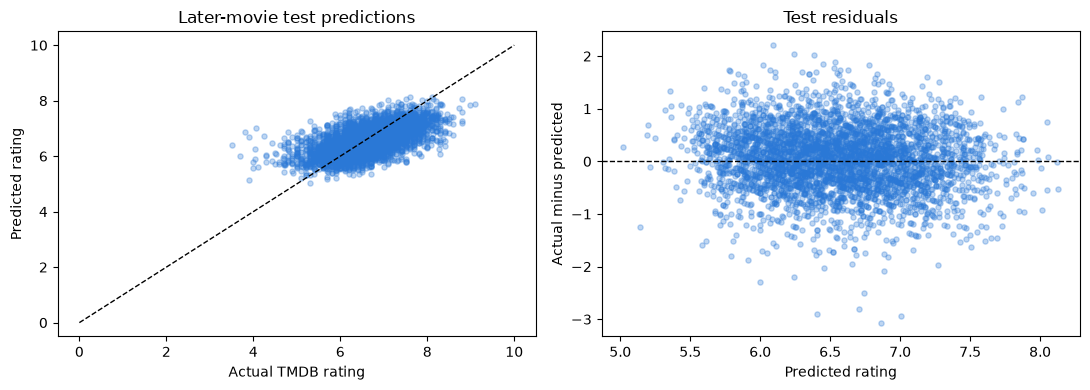

In [9]:
prediction_examples = movies.loc[test_mask, ["title_tmdb", "release_date", "vote_average"]].copy()
prediction_examples["predicted_rating"] = test_predictions
prediction_examples["residual"] = prediction_examples["vote_average"] - prediction_examples["predicted_rating"]
display(prediction_examples.head(10).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, test_predictions, alpha=0.3, s=14, color="#2a78d6")
axes[0].plot([0, 10], [0, 10], "k--", linewidth=1)
axes[0].set(xlabel="Actual TMDB rating", ylabel="Predicted rating", title="Later-movie test predictions")
axes[1].scatter(test_predictions, y_test.to_numpy() - test_predictions, alpha=0.3, s=14, color="#2a78d6")
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set(xlabel="Predicted rating", ylabel="Actual minus predicted", title="Test residuals")
plt.tight_layout()
plt.show()

## 7. Compare feature groups
Use the same Support Vector Regression and three expanding chronological validation splits within the training period. Every version uses the same movies per split and fresh training-only preprocessing. The later test period is excluded.

Start with movie characteristics, then add director, actor, and company/franchise history. Lower validation MAE/RMSE is better; positive improvement means a lower MAE than movie characteristics alone. These are cumulative comparisons, so each added group's result depends on the groups already included.

This section retains the original estimator settings to isolate the cumulative feature comparison. It does not retune each feature version. The tuning section above searches settings using all features; its selection score is not an independent estimate after selection.

In [10]:
movie_features = (
    ["runtime", "log_budget", "release_year", "n_genres", "imdb_director_count"]
    + CATEGORICAL_FEATURES
    + ["is_sequel", "is_english"]
    + [column for column in BINARY_FEATURES if column.startswith("genre_")]
)
director_features = [
    "dir_prior_success_rate_smoothed", "dir_prior_films_log1p", "dir_years_active_log1p",
    "dir_prior_known_films_log1p", "dir_first_film", "dir_no_track_record",
    "dir_prior_rating_smoothed", "dir_prior_rated_films_log1p", "dir_no_rating_history",
]
actor_features = ["lead_actor_films_5yr_backfilled_log1p", "backfill_unavailable"]
company_franchise_features = ["company_films_5yr_log1p", "franchise_prior_films_log1p"]
feature_versions = {
    "Movie characteristics": movie_features,
    "+ Director history": movie_features + director_features,
    "+ Actor history": movie_features + director_features + actor_features,
    "All features": movie_features + director_features + actor_features + company_franchise_features,
}
feature_versions = {name: feature_versions[name] for name in FEATURE_GROUPS_TO_COMPARE}
assert set(feature_versions["All features"]) == set(FEATURE_COLUMNS)
assert all(len(columns) == len(set(columns)) for columns in feature_versions.values())

In [11]:
# Split unique dates so equal release dates never appear on both sides.
training_dates = movies.loc[train_mask, "release_date"]
unique_dates = np.sort(training_dates.unique())
validation_splits = []
split_details = []
for fold, (earlier, later) in enumerate(TimeSeriesSplit(n_splits=N_VALIDATION_SPLITS).split(unique_dates), 1):
    fit_indices = training_dates.index[training_dates.isin(unique_dates[earlier])]
    validation_indices = training_dates.index[training_dates.isin(unique_dates[later])]
    assert movies.loc[fit_indices, "release_date"].max() < movies.loc[validation_indices, "release_date"].min()
    assert set(fit_indices).isdisjoint(validation_indices)
    assert set(fit_indices).union(validation_indices).issubset(set(X_train.index))
    validation_splits.append((fold, fit_indices, validation_indices))
    split_details.append({
        "Fold": fold, "Training movies": len(fit_indices), "Validation movies": len(validation_indices),
        "Training ends": movies.loc[fit_indices, "release_date"].max().date(),
        "Validation starts": movies.loc[validation_indices, "release_date"].min().date(),
        "Validation ends": movies.loc[validation_indices, "release_date"].max().date(),
    })
display(pd.DataFrame(split_details))

,Fold,Training movies,Validation movies,Training ends,Validation starts,Validation ends
0,1,2099,2292,1999-10-08,1999-10-14,2006-10-06
1,2,4391,2417,2006-10-06,2006-10-07,2012-05-09
2,3,6808,2597,2012-05-09,2012-05-10,2017-11-17


In [12]:
comparison_rows = []
for version, columns in feature_versions.items():
    for fold, fit_indices, validation_indices in validation_splits:
        candidate = make_regression_model(columns)
        candidate.fit(X_train.loc[fit_indices, columns], y_train.loc[fit_indices])
        predicted = candidate.predict(X_train.loc[validation_indices, columns])
        assert np.isfinite(predicted).all()
        comparison_rows.append({
            "Version": version, "Fold": fold, "Predictors": len(columns),
            "MAE": mean_absolute_error(y_train.loc[validation_indices], predicted),
            "RMSE": np.sqrt(mean_squared_error(y_train.loc[validation_indices], predicted)),
        })
feature_fold_results = pd.DataFrame(comparison_rows)
feature_comparison = feature_fold_results.groupby("Version", sort=False).agg(
    Predictors=("Predictors", "first"),
    Validation_MAE=("MAE", "mean"),
    MAE_std=("MAE", "std"),
    Validation_RMSE=("RMSE", "mean"),
)
feature_comparison["MAE improvement vs movie-only"] = (
    feature_comparison.loc["Movie characteristics", "Validation_MAE"] - feature_comparison["Validation_MAE"]
)
display(feature_comparison.round(4))
# Check fold consistency: a smaller overall mean can hide a worse individual period.
display(feature_fold_results.pivot(index="Version", columns="Fold", values="MAE").reindex(feature_versions).round(4))
print("Lower validation MAE/RMSE is better; MAE_std shows variation across the three periods.")

,Predictors,Validation_MAE,MAE_std,Validation_RMSE,MAE improvement vs movie-only
Version,,,,,
Movie characteristics,27,0.5327,0.0553,0.6870,0.0000
+ Director history,36,0.5158,0.0406,0.6654,0.0169
+ Actor history,38,0.5137,0.0404,0.6640,0.0190
All features,40,0.5135,0.0387,0.6629,0.0192


Fold,1,2,3
Version,,,
Movie characteristics,0.5965,0.5034,0.4982
+ Director history,0.5621,0.4987,0.4865
+ Actor history,0.5598,0.4969,0.4843
All features,0.5579,0.4949,0.4876


Lower validation MAE/RMSE is better; MAE_std shows variation across the three periods.


## 8. Does earlier director rating history help?
Compare the previous 36 predictors with the same set plus the three new director-rating-history features. Use **identical initial estimator settings**, the same rows, and the same three chronological training-period folds. This isolates the added feature block from hyperparameter and threshold changes.

Report validation and later-test MAE/RMSE/R² for both versions. This comparison is exploratory, not independent confirmation after repeated data inspection. History is updated through time using earlier-year films; historical availability of snapshot ratings is not verified. The test comparison is descriptive and does not select a version.

In [13]:
DIRECTOR_RATING_FEATURES = [
    "dir_prior_rating_smoothed", "dir_prior_rated_films_log1p", "dir_no_rating_history",
]
rating_history_versions = {
    "Without director rating history": [column for column in FEATURE_COLUMNS if column not in DIRECTOR_RATING_FEATURES],
    "With director rating history": FEATURE_COLUMNS,
}
assert len(rating_history_versions["With director rating history"]) - len(rating_history_versions["Without director rating history"]) == 3
rating_history_fold_rows = []
rating_history_test_rows = []
for version, columns in rating_history_versions.items():
    for fold, (fit_positions, validation_positions) in enumerate(tuning_splits, 1):
        candidate = make_regression_model(columns)
        candidate.fit(X_train.iloc[fit_positions], y_train.iloc[fit_positions])
        predicted = candidate.predict(X_train.iloc[validation_positions])
        metrics = score_predictions(version, "Validation", y_train.iloc[validation_positions], predicted)
        rating_history_fold_rows.append({"Version": version, "Fold": fold, **{key: metrics[key] for key in ["MAE", "RMSE", "R2"]}})
    candidate = make_regression_model(columns)
    candidate.fit(X_train, y_train)
    predicted = candidate.predict(X_test)
    rating_history_test_rows.append(score_predictions(version, "Test", y_test, predicted))

rating_history_fold_results = pd.DataFrame(rating_history_fold_rows)
rating_history_validation = rating_history_fold_results.groupby("Version", sort=False).agg(
    Validation_MAE=("MAE", "mean"), MAE_std=("MAE", "std"),
    Validation_RMSE=("RMSE", "mean"), Validation_R2=("R2", "mean"),
)
rating_history_test_results = pd.DataFrame(rating_history_test_rows)
display(rating_history_validation.round(4))
display(rating_history_test_results.round(4))
validation_gain = rating_history_validation.iloc[0]["Validation_MAE"] - rating_history_validation.iloc[1]["Validation_MAE"]
test_gain = rating_history_test_results.iloc[0]["MAE"] - rating_history_test_results.iloc[1]["MAE"]
print(f"MAE reduction from director rating history — validation: {validation_gain:+.4f}; later test: {test_gain:+.4f}")
print("Positive reduction means lower error. No version is selected using these test results.")

,Validation_MAE,MAE_std,Validation_RMSE,Validation_R2
Version,,,,
Without director rating history,0.5267,0.0431,0.6801,0.2855
With director rating history,0.5135,0.0387,0.6629,0.3215


,Model,Split,MAE,RMSE,R2
0,Without director rating history,Test,0.4914,0.6248,0.3016
1,With director rating history,Test,0.4849,0.6174,0.3180


MAE reduction from director rating history — validation: +0.0132; later test: +0.0064
Positive reduction means lower error. No version is selected using these test results.


## Interpretation and limits
Compare test MAE/RMSE with the mean-rating baseline and the corresponding linear-model scores. Use training-period validation, not repeated test inspection, to compare settings. The feature table is cumulative: it does not isolate individual transformations or establish causal importance.

The rating sample includes matched rated movies regardless of finances; it is not all TMDB movies. Earlier-year histories update through time, representing rolling predictions; a single forecast at a cutoff needs history frozen there. Retrospective data does not establish when outcomes were reported. The later test period has already been inspected and remains exploratory.

This notebook predicts ratings only; binary hit/bust classification belongs in `../success_models/`; clustering and the app are separate steps.

## Refresh the visualization report
This final cell saves metrics and prediction summaries for [the visualization notebook](../../Data_visualization/model_visualizations.ipynb). It does not write or modify dataset CSVs. Save this notebook before running all cells so report freshness checks match the code.

In [14]:
from pathlib import Path
import importlib.util

report_module_path = Path("../../Data_visualization/model_reports.py")
report_spec = importlib.util.spec_from_file_location("project_model_reports", report_module_path)
report_tools = importlib.util.module_from_spec(report_spec)
report_spec.loader.exec_module(report_tools)
report_path = report_tools.save_model_report(globals(), Path("support_vector.ipynb"))
print("Visualization report saved:", report_path)

Visualization report saved: /Users/waltroou/DS-6021/DS_Final_Project/DS6021_Group2_FinalProject/Data_visualization/results/rating/support_vector.json
